# Proyek 1: K-Means Clustering dengan Euclidean Distance (L2 Norm) pada Dataset BISINDO

**Metrik Jarak:** Euclidean Distance (L2)  
**Representasi Fitur:** 127 Dimensi MediaPipe (42 Titik 3D + Is_Two_Handed)  
**Jumlah Klaster:** K = 26 (Alfabet A-Z)  
**Fungsi Objektif:** Within-Cluster Sum of Squares (WCSS / SSE)  
**Output Target:** `outputKmeans/elbow_euclidean.png`, `outputKmeans/cluster_euclidean.png`, `outputKmeans/evaluasi_kmeans_euclidean.xlsx`

---

## 1. Landasan Teori & Formulasi Matematis

Jarak Euclidean garis lurus antara dua vektor gestur $x, y \in \mathbb{R}^{127}$:
$$d_{\text{Euclidean}}(x, y) = \|x - y\|_2 = \sqrt{\sum_{i=1}^{127} (x_i - y_i)^2}$$

Fungsi biaya yang diminimalkan secara iteratif:
$$J_{\text{Euclidean}} = \sum_{k=1}^{26} \sum_{x \in S_k} \|x - \mu_k\|_2^2$$

Pembaruan posisi titik pusat $\mu_k$ menggunakan rata-rata aritmetika analitis:
$$\mu_k^* = \frac{1}{|S_k|} \sum_{x \in S_k} x$$

In [1]:
# =======================================================================
# 1. SETUP LINGKUNGAN & PUSTAKA
# =======================================================================
import os
import sys
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    pairwise_distances
)

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

BASE_DIR = os.path.dirname(os.path.abspath(__file__)) if '__file__' in locals() else os.getcwd()
OUTPUT_DIR = os.path.join(BASE_DIR, "outputKmeans")
os.makedirs(OUTPUT_DIR, exist_ok=True)
RANDOM_STATE = 42
K_BENCHMARK = 26
np.random.seed(RANDOM_STATE)

print(f"[INFO] Direktori: {BASE_DIR} | K Benchmark = {K_BENCHMARK}")

[INFO] Direktori: E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\KMeans | K Benchmark = 26


In [2]:
# =======================================================================
# PEMUATAN DATASET BISINDO LANDMARKS (127 FITUR)
# =======================================================================
npz_path = os.path.join(BASE_DIR, "dataset_bisindo_landmarks.npz")
csv_path = os.path.join(BASE_DIR, "dataset_bisindo_landmarks.csv")

if os.path.exists(npz_path):
    data = np.load(npz_path, allow_pickle=True)
    X = data['X'].astype(np.float32)
    labels = data['labels']
    df_meta = pd.DataFrame({'label': labels, 'is_two_handed': data['is_two_handed']})
elif os.path.exists(csv_path):
    df_full = pd.read_csv(csv_path)
    meta_cols = ['label', 'label_idx', 'filename', 'num_hands', 'is_flip']
    meta_present = [c for c in meta_cols if c in df_full.columns]
    df_meta = df_full[meta_present]
    feat_cols = [c for c in df_full.columns if c not in meta_cols]
    X = df_full[feat_cols].values.astype(np.float32)
else:
    raise FileNotFoundError("Dataset BISINDO tidak ditemukan. Jalankan extract_features.py.")

print(f"[INFO] Dataset BISINDO dimuat: {X.shape[0]} sampel, {X.shape[1]} dimensi fitur.")

# Standarisasi fitur zero-mean, unit-variance
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("[INFO] Fitur berhasil distandardisasi menggunakan StandardScaler.")

[INFO] Dataset BISINDO dimuat: 7893 sampel, 127 dimensi fitur.
[INFO] Fitur berhasil distandardisasi menggunakan StandardScaler.


[ELBOW] Menghitung inersia SSE Euclidean...


[SAVE] Grafik disimpan ke: 'E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\KMeans\outputKmeans\elbow_euclidean.png'


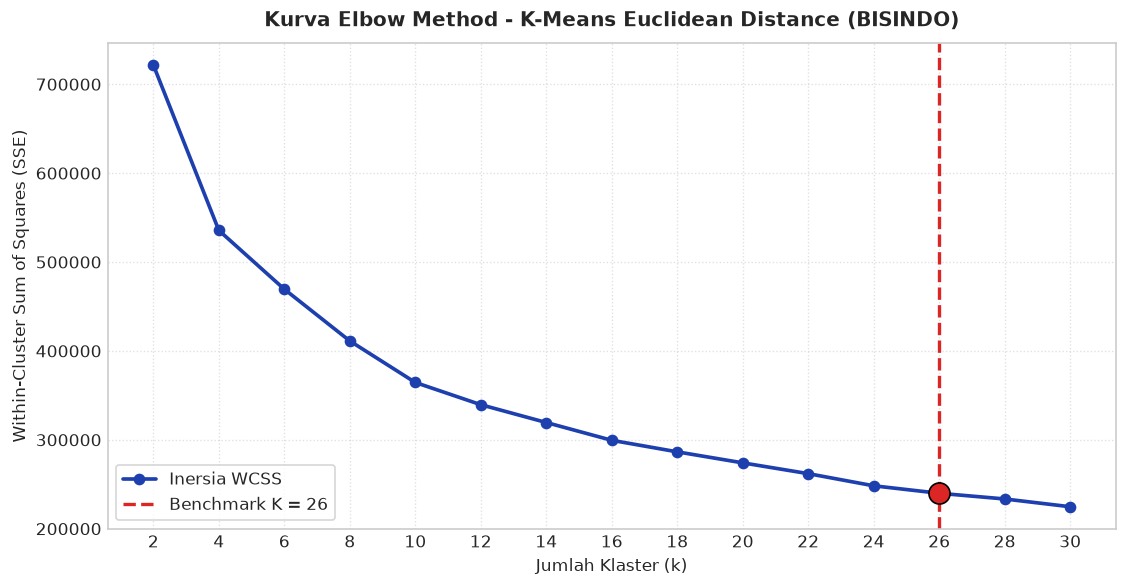

In [3]:
# =======================================================================
# 2. KURVA ELBOW METHOD EUCLIDEAN
# =======================================================================
k_range = list(range(2, 32, 2))
if K_BENCHMARK not in k_range:
    k_range.append(K_BENCHMARK)
k_range = sorted(k_range)

sse_euclidean = []
print("[ELBOW] Menghitung inersia SSE Euclidean...")
for k in k_range:
    km = KMeans(n_clusters=k, init='k-means++', n_init=5, max_iter=200, random_state=RANDOM_STATE)
    km.fit(X_scaled)
    sse_euclidean.append(km.inertia_)

plt.figure(figsize=(9.5, 5))
plt.plot(k_range, sse_euclidean, marker='o', linewidth=2.2, color='#1E40AF', label='Inersia WCSS')
plt.axvline(x=K_BENCHMARK, color='#DC2626', linestyle='--', linewidth=2, label=f'Benchmark K = {K_BENCHMARK}')

idx_26 = k_range.index(K_BENCHMARK)
plt.scatter([K_BENCHMARK], [sse_euclidean[idx_26]], color='#DC2626', s=160, zorder=5, edgecolor='black')

plt.title('Kurva Elbow Method - K-Means Euclidean Distance (BISINDO)', fontsize=12, fontweight='bold', pad=10)
plt.xlabel('Jumlah Klaster (k)', fontsize=10)
plt.ylabel('Within-Cluster Sum of Squares (SSE)', fontsize=10)
plt.xticks(k_range)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(frameon=True, facecolor='white')
plt.tight_layout()

elbow_path = os.path.join(OUTPUT_DIR, "elbow_euclidean.png")
plt.savefig(elbow_path, dpi=300)
print(f"[SAVE] Grafik disimpan ke: '{elbow_path}'")
plt.show()

In [4]:
# =======================================================================
# 3. IMPLEMENTASI DAN PELATIHAN K-MEANS EUCLIDEAN PADA K = 26
# =======================================================================
class KMeansEuclidean:
    def __init__(self, n_clusters=26, max_iter=300, tol=1e-4, random_state=42):
        self.n_clusters = n_clusters
        self.max_iter = max_iter
        self.tol = tol
        self.random_state = random_state
        self.centroids = None
        self.labels_ = None
        self.inertia_ = 0.0
        self.n_iter_ = 0
        self.execution_time_ = 0.0

    def fit(self, X):
        start = time.perf_counter()
        rng = np.random.RandomState(self.random_state)
        n_samples = len(X)
        
        # Inisialisasi K-Means++
        centroids = [X[rng.randint(n_samples)]]
        for _ in range(1, self.n_clusters):
            dists = pairwise_distances(X, np.array(centroids), metric='euclidean')
            min_d = np.min(dists, axis=1) ** 2
            probs = min_d / np.sum(min_d)
            centroids.append(X[rng.choice(n_samples, p=probs)])
        self.centroids = np.array(centroids)

        for it in range(self.max_iter):
            self.n_iter_ = it + 1
            dists = pairwise_distances(X, self.centroids, metric='euclidean')
            labels = np.argmin(dists, axis=1)

            new_c = np.zeros_like(self.centroids)
            for k in range(self.n_clusters):
                pts = X[labels == k]
                new_c[k] = np.mean(pts, axis=0) if len(pts) > 0 else X[rng.randint(n_samples)]

            if np.linalg.norm(new_c - self.centroids) < self.tol:
                self.centroids = new_c
                self.labels_ = labels
                break
            self.centroids = new_c
            self.labels_ = labels

        final_d = pairwise_distances(X, self.centroids, metric='euclidean')
        self.inertia_ = float(np.sum(final_d[np.arange(len(X)), self.labels_] ** 2))
        self.execution_time_ = float(time.perf_counter() - start)
        return self

print("[PELATIHAN] Melatih KMeans Euclidean K=26...")
model_euc = KMeansEuclidean(n_clusters=K_BENCHMARK, random_state=RANDOM_STATE).fit(X_scaled)
print(f"[SELESAI] Konvergen dalam {model_euc.n_iter_} iterasi ({model_euc.execution_time_:.3f}s)")

[PELATIHAN] Melatih KMeans Euclidean K=26...


[SELESAI] Konvergen dalam 49 iterasi (0.256s)


In [5]:
# =======================================================================
# 4. EVALUASI METRIK DAN EKSPOR LAPORAN EXCEL
# =======================================================================
sil = float(silhouette_score(X_scaled, model_euc.labels_, metric='euclidean'))
db = float(davies_bouldin_score(X_scaled, model_euc.labels_))
ch = float(calinski_harabasz_score(X_scaled, model_euc.labels_))

df_res = pd.DataFrame([{
    'Distance Metric': 'Euclidean Distance (L2)',
    'Clusters (K)': K_BENCHMARK,
    'Silhouette Score (↑)': round(sil, 4),
    'Davies–Bouldin Index (↓)': round(db, 4),
    'Calinski–Harabasz Index (↑)': round(ch, 2),
    'Execution Time (s) (↓)': round(model_euc.execution_time_, 4),
    'Iterations (↓)': model_euc.n_iter_,
    'Objective Value (SSE)': round(model_euc.inertia_, 2)
}])

print("\n" + "="*75)
print(df_res.to_string(index=False))
print("="*75)

# Ekspor Excel
excel_out = os.path.join(OUTPUT_DIR, "evaluasi_kmeans_euclidean.xlsx")
df_data_out = df_meta.copy()
df_data_out['cluster_euclidean'] = model_euc.labels_

with pd.ExcelWriter(excel_out, engine='openpyxl') as writer:
    df_res.to_excel(writer, sheet_name='Ringkasan_Evaluasi', index=False)
    df_data_out.to_excel(writer, sheet_name='Data_Terklaster', index=False)
print(f"[SAVE] Laporan Excel disimpan ke: '{excel_out}'")


        Distance Metric  Clusters (K)  Silhouette Score (↑)  Davies–Bouldin Index (↓)  Calinski–Harabasz Index (↑)  Execution Time (s) (↓)  Iterations (↓)  Objective Value (SSE)
Euclidean Distance (L2)            26                 0.206                    1.4273                       941.27                   0.256              49              245223.38


[SAVE] Laporan Excel disimpan ke: 'E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\KMeans\outputKmeans\evaluasi_kmeans_euclidean.xlsx'


[SAVE] Grafik disimpan ke: 'E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\KMeans\outputKmeans\cluster_euclidean.png'


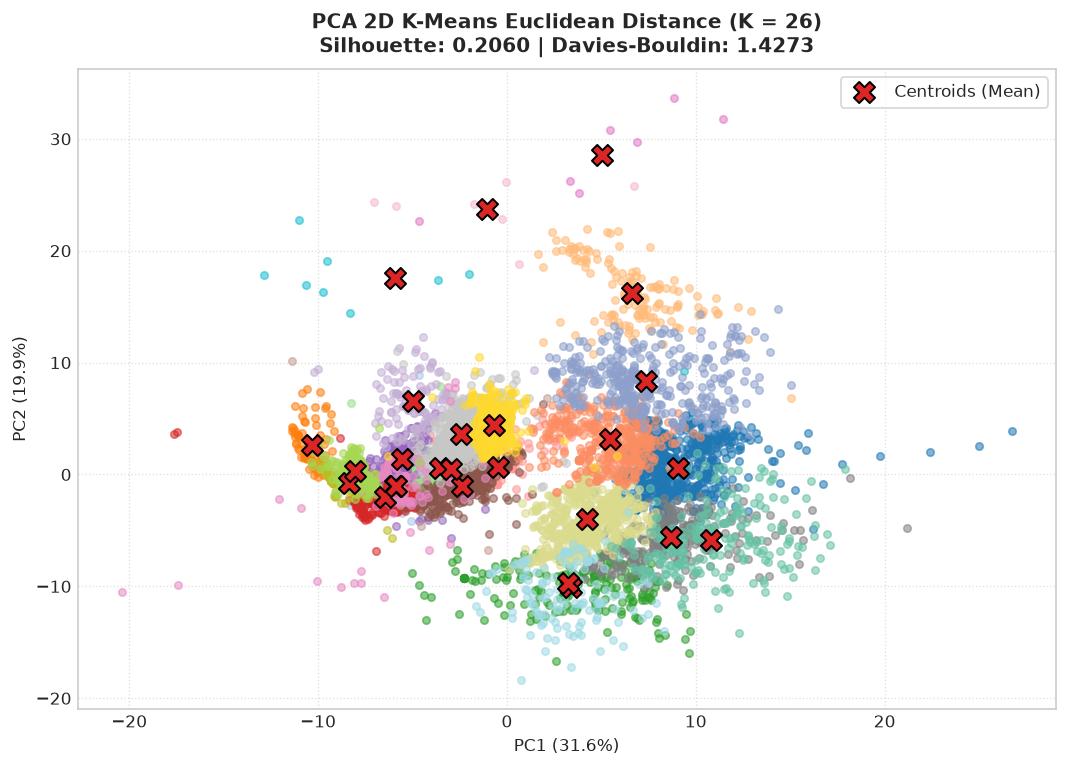

In [6]:
# =======================================================================
# 5. VISUALISASI PCA 2D KLASTERISASI EUCLIDEAN
# =======================================================================
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
centroids_pca = pca.transform(model_euc.centroids)

plt.figure(figsize=(9, 6.5))
palette = sns.color_palette("tab20", 20) + sns.color_palette("Set2", 6)

for k in range(K_BENCHMARK):
    mask = (model_euc.labels_ == k)
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1], color=palette[k % len(palette)], alpha=0.55, s=20)

plt.scatter(centroids_pca[:, 0], centroids_pca[:, 1], marker='X', s=160, c='#DC2626', edgecolor='black', linewidth=1.2, label='Centroids (Mean)', zorder=10)
plt.title(f'PCA 2D K-Means Euclidean Distance (K = {K_BENCHMARK})\nSilhouette: {sil:.4f} | Davies-Bouldin: {db:.4f}', fontsize=12, fontweight='bold', pad=10)
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(frameon=True, loc='best')
plt.tight_layout()

cluster_path = os.path.join(OUTPUT_DIR, "cluster_euclidean.png")
plt.savefig(cluster_path, dpi=300)
print(f"[SAVE] Grafik disimpan ke: '{cluster_path}'")
plt.show()